# 15 · Diffusion models: from noise to data

**Source:** *Diffusion Models: From Noise to Data* (Polaris study notes) · **Notes:** `../notes/15_diffusion_models.md`

**Core idea:** destroy data with Gaussian noise in many small, **known** steps; train a network to **predict the noise** that was added; then generate by starting from pure noise and **removing predicted noise step by step**.

In this notebook you will:
1. Check the notes' numbers (ᾱ = 0.64 → 0.8x₀ + 0.6ε; β = 0.04 → noise coefficient 0.2) and prove the **closed-form jump** equals 100 small steps.
2. Look at the notes' noise schedule: how much signal survives, and the signal-to-noise ratio.
3. Run the notes' **exact lab** (8 clusters on a ring, a small MLP, 2,500 steps) and measure whether the samples really cover all 8 modes.
4. See **why the loss can't reach zero**, measured per timestep.
5. Generate with **10 steps instead of 100** (a DDIM-style sampler, no retraining).
6. Add **class conditioning + classifier-free guidance** and measure the effect of the guidance scale w.
7. Go beyond the notes: a diffusion model that **draws handwritten digits** (8×8), and a check that it isn't just copying the training set.

Runs in about 3 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.datasets import load_digits
torch.manual_seed(7)

## 1 · The forward process in numbers

One step: **x_t = √α_t · x_{t−1} + √β_t · ε**, with α_t = 1 − β_t.
Closed form: **x_t = √ᾱ_t · x₀ + √(1 − ᾱ_t) · ε**, with ᾱ_t = α₁·α₂·…·α_t.

In [2]:
print("notes: abar = 0.64  ->  x_t =", math.sqrt(0.64), "* x0 +", round(math.sqrt(1 - 0.64), 3), "* eps")
print("exam Q1: abar = 0.81  ->  x_t =", math.sqrt(0.81), "* x0 +", round(math.sqrt(1 - 0.81), 3), "* eps   (not 0.81 and 0.19: those are VARIANCES)")
print("one step with beta = 0.04: x_t =", round(math.sqrt(0.96), 4), "* x_{t-1} +", math.sqrt(0.04), "* eps   (noise coefficient 0.2, not 0.04)")
print("check: signal variance + noise variance = 0.8^2 + 0.6^2 =", 0.8 ** 2 + 0.6 ** 2, "-> the total variance stays 1 for unit-variance data")

notes: abar = 0.64  ->  x_t = 0.8 * x0 + 0.6 * eps
exam Q1: abar = 0.81  ->  x_t = 0.9 * x0 + 0.436 * eps   (not 0.81 and 0.19: those are VARIANCES)
one step with beta = 0.04: x_t = 0.9798 * x_{t-1} + 0.2 * eps   (noise coefficient 0.2, not 0.04)
check: signal variance + noise variance = 0.8^2 + 0.6^2 = 1.0 -> the total variance stays 1 for unit-variance data


### Does one big jump really equal 100 small steps?
Take a fixed point x₀ = (3, −2), push 200,000 copies through **100 individual noise steps**, and compare their distribution with the **closed-form** prediction N(√ᾱ·x₀, (1 − ᾱ)I).

In [3]:
T = 100
beta = torch.linspace(1e-4, 0.08, T)                 # the notes' schedule
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)
x0 = torch.tensor([3.0, -2.0])
x = x0.repeat(200_000, 1)
for t in range(50):                                   # 50 small steps
    x = alpha[t].sqrt() * x + beta[t].sqrt() * torch.randn_like(x)
ab = alpha_bar[49]
print(f"after 50 small steps : mean {x.mean(0).numpy().round(3)}, std {x.std(0).numpy().round(3)}")
print(f"closed form, t = 50  : mean {(ab.sqrt() * x0).numpy().round(3)}, std {[round(math.sqrt(1 - ab.item()), 3)] * 2}")

after 50 small steps : mean [ 1.813 -1.212], std [0.797 0.798]
closed form, t = 50  : mean [ 1.813 -1.209], std [0.797, 0.797]


They match (to sampling noise). That's why training never runs the chain step by step: it **jumps straight to any t** in one line.

## 2 · The noise schedule: how fast is the signal destroyed?

t =   1: beta 0.0001   abar 0.9999   signal coef 1.000   noise coef 0.010   SNR 1e+04
t =  10: beta 0.0074   abar 0.9633   signal coef 0.981   noise coef 0.192   SNR 26.2
t =  25: beta 0.0195   abar 0.7817   signal coef 0.884   noise coef 0.467   SNR 3.58
t =  50: beta 0.0396   abar 0.3652   signal coef 0.604   noise coef 0.797   SNR 0.575
t =  75: beta 0.0598   abar 0.1009   signal coef 0.318   noise coef 0.948   SNR 0.112
t = 100: beta 0.0800   abar 0.0163   signal coef 0.128   noise coef 0.992   SNR 0.0166


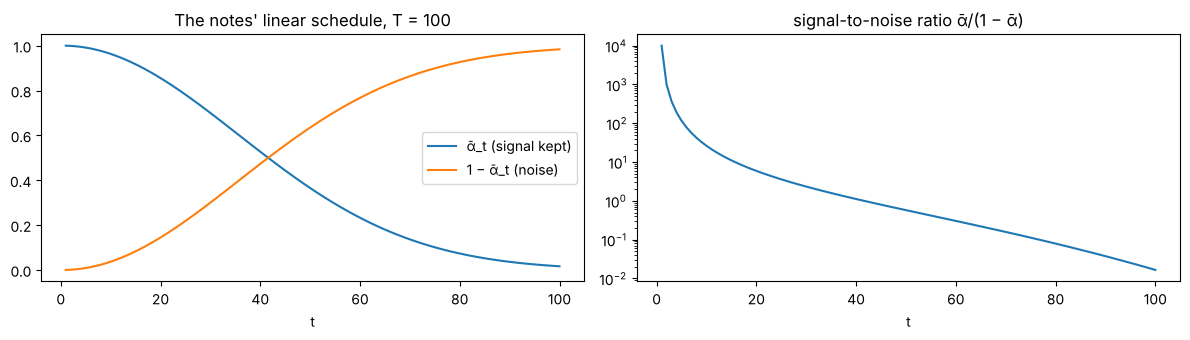

In [4]:
snr = alpha_bar / (1 - alpha_bar)
for t in [1, 10, 25, 50, 75, 100]:
    print(f"t = {t:>3}: beta {beta[t - 1]:.4f}   abar {alpha_bar[t - 1]:.4f}   signal coef {alpha_bar[t - 1].sqrt():.3f}   noise coef {(1 - alpha_bar[t - 1]).sqrt():.3f}   SNR {snr[t - 1]:.3g}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(range(1, T + 1), alpha_bar, label="ᾱ_t (signal kept)"); axes[0].plot(range(1, T + 1), 1 - alpha_bar, label="1 − ᾱ_t (noise)")
axes[0].set_xlabel("t"); axes[0].legend(); axes[0].set_title("The notes' linear schedule, T = 100")
axes[1].semilogy(range(1, T + 1), snr); axes[1].set_xlabel("t"); axes[1].set_title("signal-to-noise ratio ᾱ/(1 − ᾱ)")
plt.tight_layout(); plt.show()

- **Early steps (small t): high SNR.** At t = 10 the point is still 98% signal (SNR 26).
- **Middle (t ≈ 50): signal and noise are comparable** (coefficients 0.60 vs 0.80, SNR 0.58).
- **End (t = 100):** ᾱ = 0.016, i.e. **12.8% of the signal amplitude survives**. Close to noise, but not perfectly: the notes' table warns that "noise too slow" leaves structure at the end, while sampling starts from pure N(0, I). With only 100 steps that's a reasonable compromise here; the digits model below uses T = 200 and ends at 7.8%.
- β is tiny at first (0.0001) and largest at the end (0.08): gentle corruption while there's lots of detail, faster once little is left.

## 3 · The notes' lab: 8 clusters on a ring
Exactly the notes' code: 12,000 points, T = 100, a 4-layer MLP with SiLU, a 32-dimensional sinusoidal timestep embedding, Adam (lr 2e-3), 2,500 steps of batch 256.

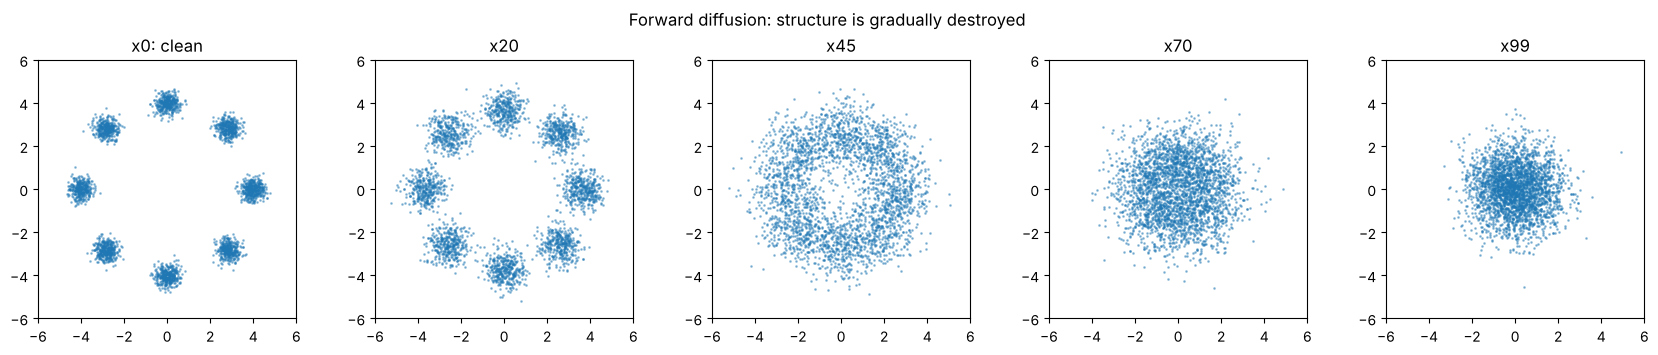

In [5]:
torch.manual_seed(7)
def make_ring_dataset(n=12000, clusters=8, radius=4.0, std=0.28):
    ids = torch.randint(0, clusters, (n,))
    angles = 2 * math.pi * ids.float() / clusters
    centers = torch.stack([radius * torch.cos(angles), radius * torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n, 2), ids

x_data, cluster_ids = make_ring_dataset()
alpha_bar_prev = torch.cat([torch.ones(1), alpha_bar[:-1]])
posterior_variance = beta * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)

def add_noise(x0, t):
    eps = torch.randn_like(x0)
    a_bar = alpha_bar[t].unsqueeze(1)
    return torch.sqrt(a_bar) * x0 + torch.sqrt(1.0 - a_bar) * eps, eps

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, t in zip(axes, [0, 20, 45, 70, 99]):
    pts = x_data[:3000] if t == 0 else add_noise(x_data[:3000], torch.full((3000,), t))[0]
    ax.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.4); ax.set_title("x0: clean" if t == 0 else f"x{t}"); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal")
plt.suptitle("Forward diffusion: structure is gradually destroyed"); plt.tight_layout(); plt.show()

In [6]:
def timestep_embedding(t, dim=32):
    half = dim // 2
    freq = torch.exp(-math.log(10000) * torch.arange(half).float() / max(half - 1, 1))
    angles = t.float().unsqueeze(1) * freq.unsqueeze(0)
    return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

class NoisePredictor(nn.Module):
    def __init__(self, time_dim=32, hidden=128, n_classes=0):
        super().__init__()
        self.n_classes = n_classes
        cond = n_classes + 1 if n_classes else 0                 # +1 = the "no condition" token (section 6)
        self.class_emb = nn.Embedding(cond, 16) if n_classes else None
        self.net = nn.Sequential(nn.Linear(2 + time_dim + (16 if n_classes else 0), hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))
    def forward(self, x_t, t, c=None):
        parts = [x_t, timestep_embedding(t, 32)]
        if self.n_classes: parts.append(self.class_emb(c))
        return self.net(torch.cat(parts, dim=1))

torch.manual_seed(7)
model = NoisePredictor()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
t0 = time.time()
for step in range(2500):
    idx = torch.randint(0, len(x_data), (256,))
    x0 = x_data[idx]; t = torch.randint(0, T, (256,))
    x_t, true_noise = add_noise(x0, t)
    loss = ((model(x_t, t) - true_noise) ** 2).mean()
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if step % 500 == 0: print(f"step {step:>4}: loss {loss.item():.4f}")
print(f"training time: {time.time() - t0:.1f} s")

parameters: 37,762
step    0: loss 0.9070


step  500: loss 0.5993


step 1000: loss 0.4389


step 1500: loss 0.4512


step 2000: loss 0.4144


training time: 5.9 s


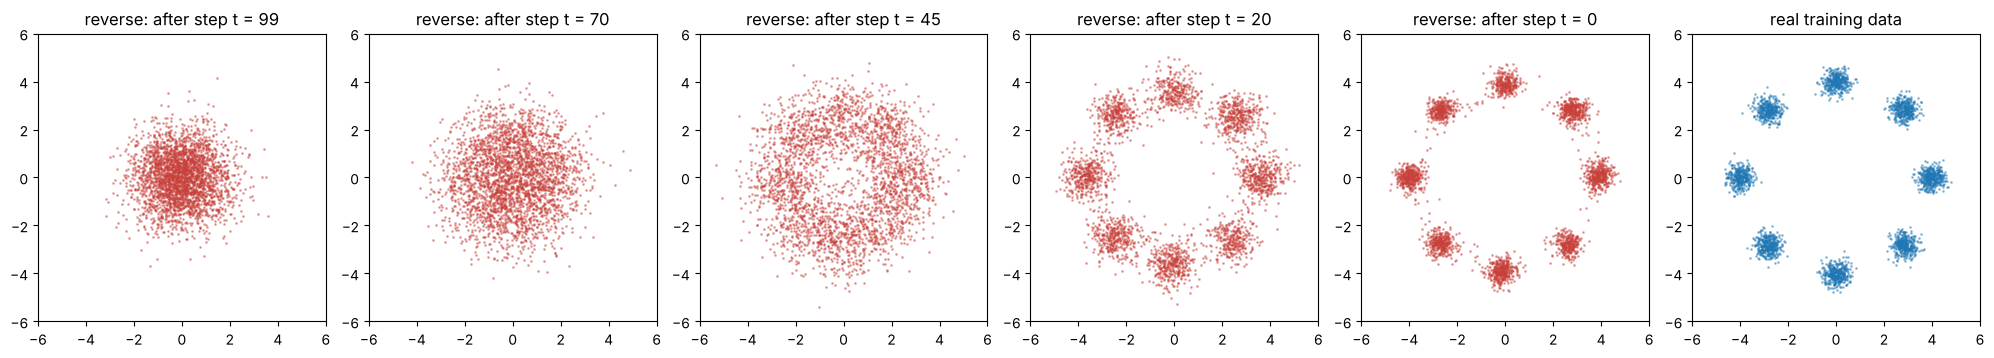

In [7]:
@torch.no_grad()
def sample(model, n=3000, c=None, w=0.0, keep=()):
    model.eval()
    x = torch.randn(n, 2); snaps = {}
    for i in reversed(range(T)):
        t = torch.full((n,), i, dtype=torch.long)
        if c is None:
            eps = model(x, t)
        else:                                                  # classifier-free guidance (section 6)
            e_c = model(x, t, c); e_u = model(x, t, torch.full_like(c, model.n_classes))
            eps = e_u + w * (e_c - e_u)
        mean = (1.0 / torch.sqrt(alpha[i])) * (x - (beta[i] / torch.sqrt(1.0 - alpha_bar[i])) * eps)
        x = mean + torch.sqrt(posterior_variance[i]) * torch.randn_like(x) if i > 0 else mean
        if i in keep: snaps[i] = x.clone()
    return x, snaps

torch.manual_seed(0)
gen, snaps = sample(model, keep=(99, 70, 45, 20, 0))
fig, axes = plt.subplots(1, 6, figsize=(20, 3.4))
for ax, i in zip(axes, [99, 70, 45, 20, 0]):
    ax.scatter(snaps[i][:, 0], snaps[i][:, 1], s=1, alpha=0.4, c="#c8403a"); ax.set_title(f"reverse: after step t = {i}"); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal")
axes[5].scatter(x_data[:3000, 0], x_data[:3000, 1], s=1, alpha=0.4); axes[5].set_title("real training data"); axes[5].set_xlim(-6, 6); axes[5].set_ylim(-6, 6); axes[5].set_aspect("equal")
plt.tight_layout(); plt.show()

### Did it really learn the distribution? Measure it
For each generated point: distance to the nearest of the 8 true cluster centres. If the model learned the distribution, the points should sit near centres (like the data, whose spread is std 0.28) and be shared **evenly** across all 8 modes (no mode left empty).

In [8]:
angles = 2 * math.pi * torch.arange(8).float() / 8
centers = torch.stack([4 * torch.cos(angles), 4 * torch.sin(angles)], 1)
def mode_stats(pts):
    d = torch.cdist(pts, centers); nearest = d.argmin(1); dist = d.min(1).values
    counts = torch.bincount(nearest, minlength=8)
    return dist, counts
d_real, c_real = mode_stats(x_data[:3000]); d_gen, c_gen = mode_stats(gen)
print(f"median distance to nearest centre: real {d_real.median():.3f}   generated {d_gen.median():.3f}")
print(f"share of points within 1.0 of a centre: real {(d_real < 1).float().mean():.1%}   generated {(d_gen < 1).float().mean():.1%}")
print("points per mode (generated):", c_gen.tolist(), " (ideal ≈", 3000 // 8, "each)")
print("points per mode (real)     :", c_real.tolist())

median distance to nearest centre: real 0.327   generated 0.355
share of points within 1.0 of a centre: real 99.9%   generated 97.8%
points per mode (generated): [415, 410, 320, 338, 418, 382, 400, 317]  (ideal ≈ 375 each)
points per mode (real)     : [402, 380, 371, 355, 359, 379, 383, 371]


**Measured:**
- **37,762 parameters**, trained in **~6 seconds** (the notes report ~7 s).
- The loss settled around **0.41** and never approached 0 (section 4 explains why).
- Generated points sit almost as tightly around the centres as the real data (median distance **0.355** vs 0.327), and **97.8%** are within 1.0 of a centre (real: 99.9%).
- **All 8 modes are covered**, 317 to 418 points each (ideal 375). No mode collapse: diffusion models are known for this, in contrast to GANs, which often drop modes (see `computer-vision/week-4-gans`).
- It learned the **probability structure**, not individual points: these are new coordinates, not copies.

## 4 · Why the loss never reaches zero
The notes say: "at high noise levels, multiple clean samples can plausibly explain a noisy point; the optimal predictor is statistical". Measure the trained model's error **separately for each noise level**:

In [9]:
torch.manual_seed(1)
with torch.no_grad():
    rows = []
    for t_val in [0, 5, 10, 25, 50, 75, 99]:
        x0 = x_data[torch.randint(0, len(x_data), (5000,))]; t = torch.full((5000,), t_val)
        x_t, eps = add_noise(x0, t)
        rows.append((t_val, ((model(x_t, t) - eps) ** 2).mean().item()))
for t_val, l in rows:
    print(f"t = {t_val:>2} (SNR {snr[t_val]:9.3g}): noise-prediction MSE {l:.3f}")

t =  0 (SNR     1e+04): noise-prediction MSE 1.040
t =  5 (SNR      78.1): noise-prediction MSE 0.897
t = 10 (SNR      21.4): noise-prediction MSE 0.669
t = 25 (SNR      3.27): noise-prediction MSE 0.372
t = 50 (SNR      0.54): noise-prediction MSE 0.562
t = 75 (SNR     0.105): noise-prediction MSE 0.431
t = 99 (SNR    0.0166): noise-prediction MSE 0.122


**A surprise worth understanding:** with **noise** prediction, the error is **largest at the lowest noise levels** (MSE ≈ 1.04 at t = 0) and **smallest at the highest** (0.12 at t = 99).
- At t = 99, x_t is 99% noise, so "predict the noise" is easy: the answer is almost x_t itself.
- At t = 0 the added noise is tiny (coefficient 0.01) compared with the natural spread of the data (0.28), so the network can't tell the noise from the data. Its best guess is ≈ 0, an error of about 1 (the variance of ε). Luckily such errors barely matter: they get multiplied by the tiny noise coefficient when x₀ is reconstructed.
- The notes' statement ("at high noise, several clean samples explain one noisy point") is true for the **clean data** x₀: that's what is ambiguous at high t. Both views agree on the main lesson: **some error is irreducible, so the loss never reaches 0**.

## 5 · Fewer sampling steps without retraining (DDIM-style)
The **trained network** and the **sampler** are separate. A deterministic DDIM-style sampler can jump between widely spaced timesteps: here **10** network calls instead of 100.

DDIM step from t to an earlier s: predict x̂₀ = (x_t − √(1 − ᾱ_t)·ε̂) / √ᾱ_t, then x_s = √ᾱ_s·x̂₀ + √(1 − ᾱ_s)·ε̂.

DDPM, 100 steps     210 ms   median distance to a centre 0.355   within 1.0: 97.8%   empty modes: 0


DDIM, 50 steps      277 ms   median distance to a centre 0.350   within 1.0: 95.6%   empty modes: 0
DDIM, 10 steps       14 ms   median distance to a centre 0.341   within 1.0: 93.4%   empty modes: 0
DDIM, 3 steps         7 ms   median distance to a centre 0.940   within 1.0: 53.8%   empty modes: 0


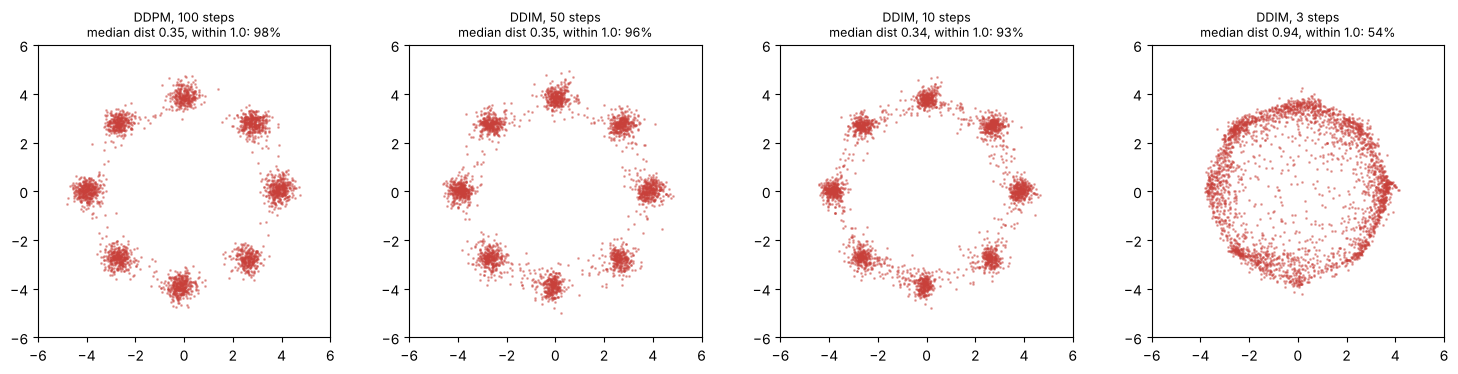

In [10]:
@torch.no_grad()
def ddim(model, n=3000, steps=10):
    ts = torch.linspace(T - 1, 0, steps).round().long().tolist()
    x = torch.randn(n, 2)
    for k, t_ in enumerate(ts):
        eps = model(x, torch.full((n,), t_, dtype=torch.long))
        x0_hat = (x - (1 - alpha_bar[t_]).sqrt() * eps) / alpha_bar[t_].sqrt()
        if k + 1 < len(ts):
            s = ts[k + 1]; x = alpha_bar[s].sqrt() * x0_hat + (1 - alpha_bar[s]).sqrt() * eps
        else:
            x = x0_hat
    return x

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, fn) in zip(axes, [("DDPM, 100 steps", lambda: sample(model)[0]), ("DDIM, 50 steps", lambda: ddim(model, steps=50)),
                                 ("DDIM, 10 steps", lambda: ddim(model, steps=10)), ("DDIM, 3 steps", lambda: ddim(model, steps=3))]):
    torch.manual_seed(0); t0 = time.time(); pts = fn(); secs = time.time() - t0
    dist, counts = mode_stats(pts)
    ax.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.4, c="#c8403a"); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal")
    ax.set_title(f"{name}\nmedian dist {dist.median():.2f}, within 1.0: {(dist < 1).float().mean():.0%}", fontsize=9)
    print(f"{name:<16} {secs * 1000:6.0f} ms   median distance to a centre {dist.median():.3f}   within 1.0: {(dist < 1).float().mean():.1%}   empty modes: {(counts == 0).sum().item()}")
plt.tight_layout(); plt.show()

- **10 deterministic DDIM steps** gave results as good as the full **100-step** DDPM sampler (93% vs 98% of points within 1.0 of a centre, median distance 0.34 vs 0.36, no empty modes), about **15× faster**. Same network, **no retraining**: "you can often change the sampler at inference without retraining".
- **3 steps** is too few: points smear between clusters (only 54% near a centre). "More steps always better" is false, but "fewer is free" is false too: there's a sweet spot.
- Remember the three different numbers: **T = 100 training timesteps**, **10 sampling steps**, **37,762 parameters**.

## 6 · Conditioning and classifier-free guidance (CFG)
Now ask for a **specific** cluster. The network gets a class label c (which of the 8 clusters). During training the label is **dropped 15% of the time** (replaced by a "no condition" token), so the same network learns both ε(x_t, t, c) and ε(x_t, t). At sampling time:

**ε_guided = ε_uncond + w·(ε_cond − ε_uncond)**

guidance w = 0.0 :  14.6% of samples land in the requested cluster 2   spread inside it 0.525 (data: 0.28)


guidance w = 1.0 : 100.0% of samples land in the requested cluster 2   spread inside it 0.286 (data: 0.28)


guidance w = 3.0 : 100.0% of samples land in the requested cluster 2   spread inside it 0.257 (data: 0.28)


guidance w = 8.0 : 100.0% of samples land in the requested cluster 2   spread inside it 0.234 (data: 0.28)


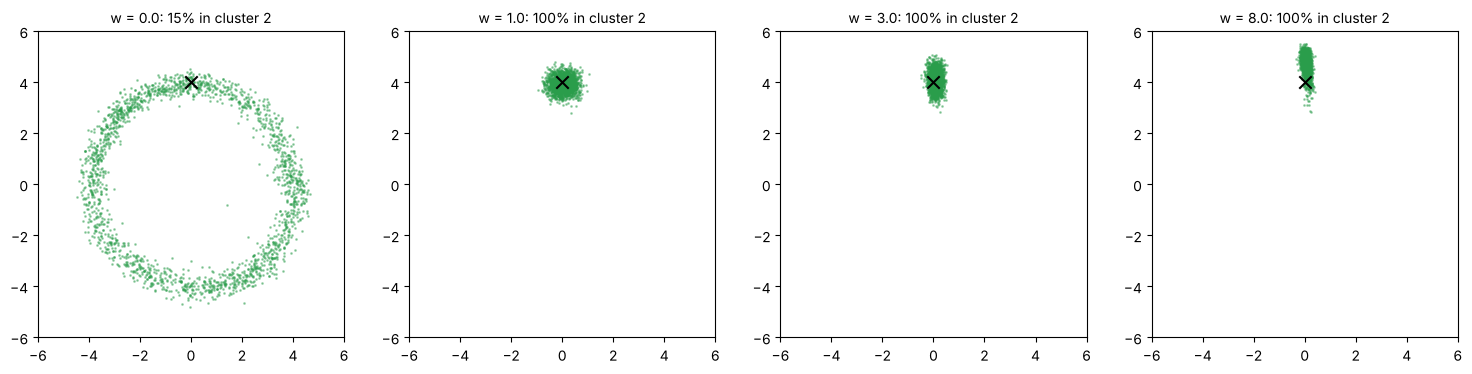

In [11]:
torch.manual_seed(7)
cmodel = NoisePredictor(n_classes=8)
copt = torch.optim.Adam(cmodel.parameters(), lr=2e-3)
for step in range(4000):
    idx = torch.randint(0, len(x_data), (256,))
    x0, c = x_data[idx], cluster_ids[idx].clone()
    c[torch.rand(256) < 0.15] = 8                              # drop the condition 15% of the time
    t = torch.randint(0, T, (256,)); x_t, eps = add_noise(x0, t)
    loss = ((cmodel(x_t, t, c) - eps) ** 2).mean(); copt.zero_grad(); loss.backward(); copt.step()

target = 2
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, w in zip(axes, [0.0, 1.0, 3.0, 8.0]):
    torch.manual_seed(0)
    pts, _ = sample(cmodel, n=2000, c=torch.full((2000,), target), w=w)
    dist, counts = mode_stats(pts); nearest = torch.cdist(pts, centers).argmin(1)
    hit = (nearest == target).float().mean().item()
    spread = pts[nearest == target].std(0).mean().item()
    ax.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.4, c="#2a9d4b"); ax.scatter(*centers[target], marker="x", c="k", s=80)
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal"); ax.set_title(f"w = {w}: {hit:.0%} in cluster {target}", fontsize=10)
    print(f"guidance w = {w:<4}: {hit:6.1%} of samples land in the requested cluster {target}   spread inside it {spread:.3f} (data: 0.28)")
plt.tight_layout(); plt.show()

**Measured (asking for cluster 2):**

| w | in the requested cluster | spread inside it (data: 0.28) |
|---|---|---|
| 0 (unconditional) | 14.6% (≈ 1/8, random) | 0.53 |
| 1 (plain conditional) | **100%** | 0.286 |
| 3 | 100% | 0.257 |
| 8 | 100% | **0.234** |

- **w = 0** ignores the condition: samples land anywhere (14.6% ≈ 1 in 8).
- **w = 1** already hits the right cluster every time, with the **natural spread** of the data.
- **Larger w** squeezes the samples **tighter than the real data** (0.234 < 0.28): stronger alignment, **less diversity**, exactly the notes' "too high can reduce diversity". In image models the same effect gives over-saturated, "too perfect" pictures.
- **One** network learned both modes thanks to the 15% label dropout, so no separate classifier was needed.

## 7 · Beyond the notes: a diffusion model that draws digits
Same training loop, same sampler, but the data is the 1,797 **8×8 handwritten digits** (64 numbers per image, scaled to [−1, 1]), T = 200, and a bigger MLP. A real image model would use a U-Net or a transformer (DiT), and usually a latent space; an MLP is enough at 8×8.

abar at T = 200: 0.0061  (signal coefficient 0.078: x_T is essentially pure noise)
step 0: loss 1.003


step 2000: loss 0.181


step 4000: loss 0.158


step 6000: loss 0.151


trained in 56 s, 624,192 parameters


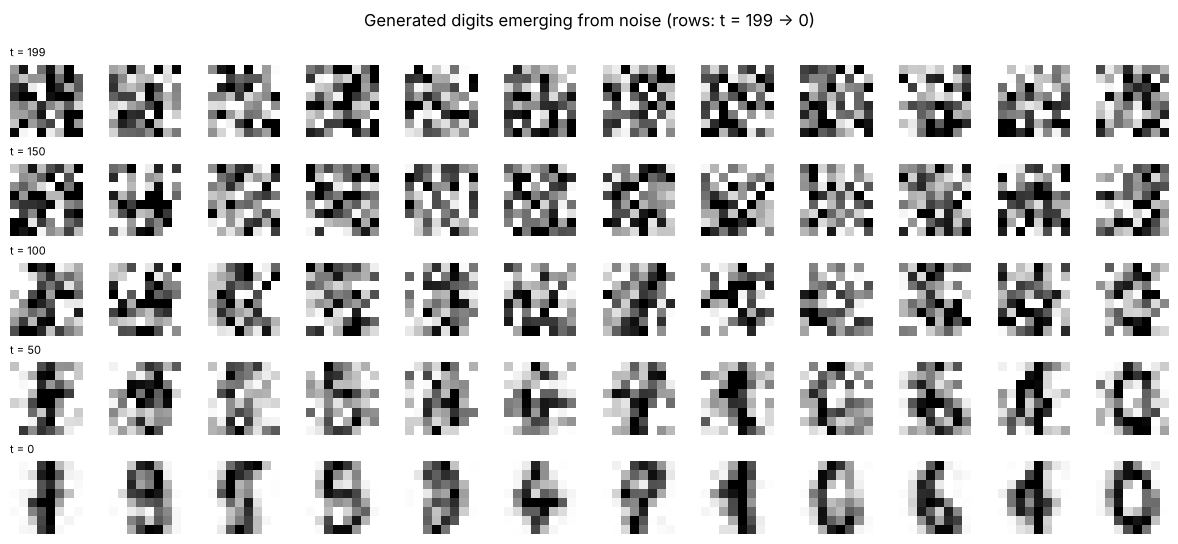

In [12]:
torch.manual_seed(0)
Xd = torch.tensor(load_digits().data / 8.0 - 1.0, dtype=torch.float32)
Td = 200
beta_d = torch.linspace(1e-4, 0.05, Td); alpha_d = 1 - beta_d; ab_d = torch.cumprod(alpha_d, 0)
pv_d = beta_d * (1 - torch.cat([torch.ones(1), ab_d[:-1]])) / (1 - ab_d)
print(f"abar at T = {Td}: {ab_d[-1]:.4f}  (signal coefficient {ab_d[-1].sqrt():.3f}: x_T is essentially pure noise)")
dnet = nn.Sequential(nn.Linear(64 + 64, 512), nn.SiLU(), nn.Linear(512, 512), nn.SiLU(), nn.Linear(512, 512), nn.SiLU(), nn.Linear(512, 64))
dopt = torch.optim.AdamW(dnet.parameters(), lr=1e-3)
emb = lambda t: timestep_embedding(t, 64)
t0 = time.time()
for step in range(8000):
    x0 = Xd[torch.randint(0, len(Xd), (256,))]; t = torch.randint(0, Td, (256,)); e = torch.randn_like(x0)
    xt = ab_d[t].sqrt()[:, None] * x0 + (1 - ab_d[t]).sqrt()[:, None] * e
    loss = ((dnet(torch.cat([xt, emb(t)], 1)) - e) ** 2).mean(); dopt.zero_grad(); loss.backward(); dopt.step()
    if step % 2000 == 0: print(f"step {step}: loss {loss.item():.3f}")
print(f"trained in {time.time() - t0:.0f} s, {sum(p.numel() for p in dnet.parameters()):,} parameters")

with torch.no_grad():
    torch.manual_seed(3); x = torch.randn(48, 64); frames = {}
    for i in reversed(range(Td)):
        eps = dnet(torch.cat([x, emb(torch.full((48,), i))], 1))
        x = (x - beta_d[i] / (1 - ab_d[i]).sqrt() * eps) / alpha_d[i].sqrt() + (pv_d[i].sqrt() * torch.randn_like(x) if i > 0 else 0)
        if i in (199, 150, 100, 50, 0): frames[i] = x.clone()
fig, axes = plt.subplots(5, 12, figsize=(12, 5.5))
for r, i in enumerate([199, 150, 100, 50, 0]):
    for k in range(12):
        axes[r, k].imshow(frames[i][k].clamp(-1, 1).view(8, 8), cmap="gray_r"); axes[r, k].axis("off")
    axes[r, 0].set_title(f"t = {i}", fontsize=8, loc="left")
plt.suptitle("Generated digits emerging from noise (rows: t = 199 → 0)"); plt.tight_layout(); plt.show()

distance from a generated digit to its nearest training digit: median 2.47
distance from a real digit to its nearest OTHER training digit : median 2.02
generated digits that are near-copies (distance < 0.5): 0 of 48


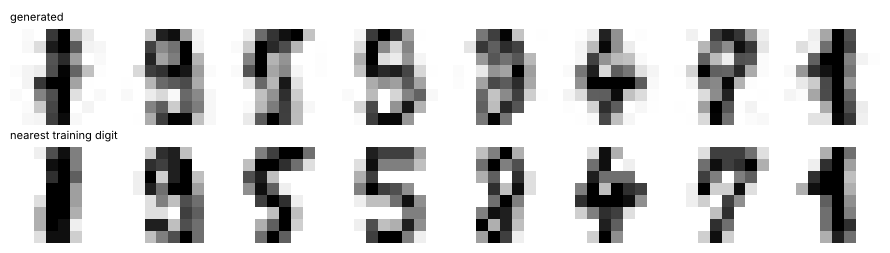

In [13]:
gen_d = x.clamp(-1, 1)
d_gen = torch.cdist(gen_d, Xd).min(1).values
dd = torch.cdist(Xd[:500], Xd); dd[torch.arange(500), torch.arange(500)] = 1e9
d_real = dd.min(1).values
print(f"distance from a generated digit to its nearest training digit: median {d_gen.median():.2f}")
print(f"distance from a real digit to its nearest OTHER training digit : median {d_real.median():.2f}")
print(f"generated digits that are near-copies (distance < 0.5): {(d_gen < 0.5).sum().item()} of {len(gen_d)}")
fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for k in range(8):
    j = torch.cdist(gen_d[k:k + 1], Xd).argmin().item()
    axes[0, k].imshow(gen_d[k].view(8, 8), cmap="gray_r"); axes[1, k].imshow(Xd[j].view(8, 8), cmap="gray_r")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("generated", fontsize=8, loc="left"); axes[1, 0].set_title("nearest training digit", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

**What happened:**
- **624,192 parameters**, trained in under a minute: the rows show random pixels (t = 199) turning into recognisable **0, 1, 4, 6, 9** shapes by t = 0. *The training algorithm is identical to the ring lab*; only the data shape (64 numbers instead of 2) and the network size changed, which is the notes' "moving to images" point.
- **Not memorised:** each generated digit is a median distance of **2.47** from its nearest training digit, a bit further than real digits are from each other (2.02), and **0 of 48** are near-copies. The model generates **new** digits in the style of the data. (Some are blurry or ambiguous: an MLP has no notion of neighbouring pixels. U-Nets with convolutions exist precisely for this.)

## ✅ Check yourself (the notes' questions)
1. ᾱ_t = 0.81: write x_t. Why 0.9 and 0.436, not 0.81 and 0.19? *(x_t = 0.9x₀ + 0.436ε; the square roots are standard deviations, 0.81 and 0.19 are variances)*
2. β_t = 0.04: one forward step? *(x_t = √0.96·x_{t−1} + 0.2ε)*
3. What is learned, and what is fixed? *(the network weights θ are learned; the schedule β, α, ᾱ is fixed)*
4. Why is noise-prediction MSE enough to train a generator with no "correct image" labels? *(we add the noise ourselves, so the target ε is known exactly for every example)*
5. Why can't the training loss reach zero? *(at high noise many clean points explain the same noisy point; the best prediction is an average)*
6. Training timesteps, sampling steps, parameters: three different numbers? *(yes: here T = 100 training timesteps, 10 DDIM sampling steps, 37,762 parameters)*
7. What does a large guidance scale w do? *(stronger adherence to the condition, less diversity, possible artefacts)*